Library import

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


data entry

In [5]:
import torch as tt
print ('addition')

addition


In [3]:
dataframe=pd.read_csv("data.csv")

In [8]:
dataframe.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
dataframe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:
dataframe["TotalCharges"]=dataframe["TotalCharges"].astype(float)

ValueError: could not convert string to float: ' '

In [11]:
dataframe["TotalCharges"]=pd.to_numeric(dataframe["TotalCharges"],errors="coerce")

In [12]:
dataframe.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [13]:
dataframe.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [14]:
dataframe=dataframe[dataframe['TotalCharges'].notnull()]

In [15]:
dataframe.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
op=dataframe['Churn'].value_counts()

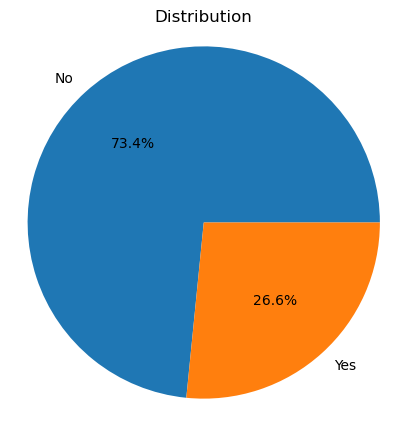

In [17]:
plt.figure(figsize=(5,5))
plt.pie(op,labels=op.index,autopct='%1.1f%%')
plt.axis('equal')
plt.title("Distribution")
plt.ylabel('')
plt.show()

In [18]:
numeric_data=dataframe[dataframe.select_dtypes(include=float).columns.to_list()]

In [19]:
n_features=['tenure','MonthlyCharges', 'TotalCharges']

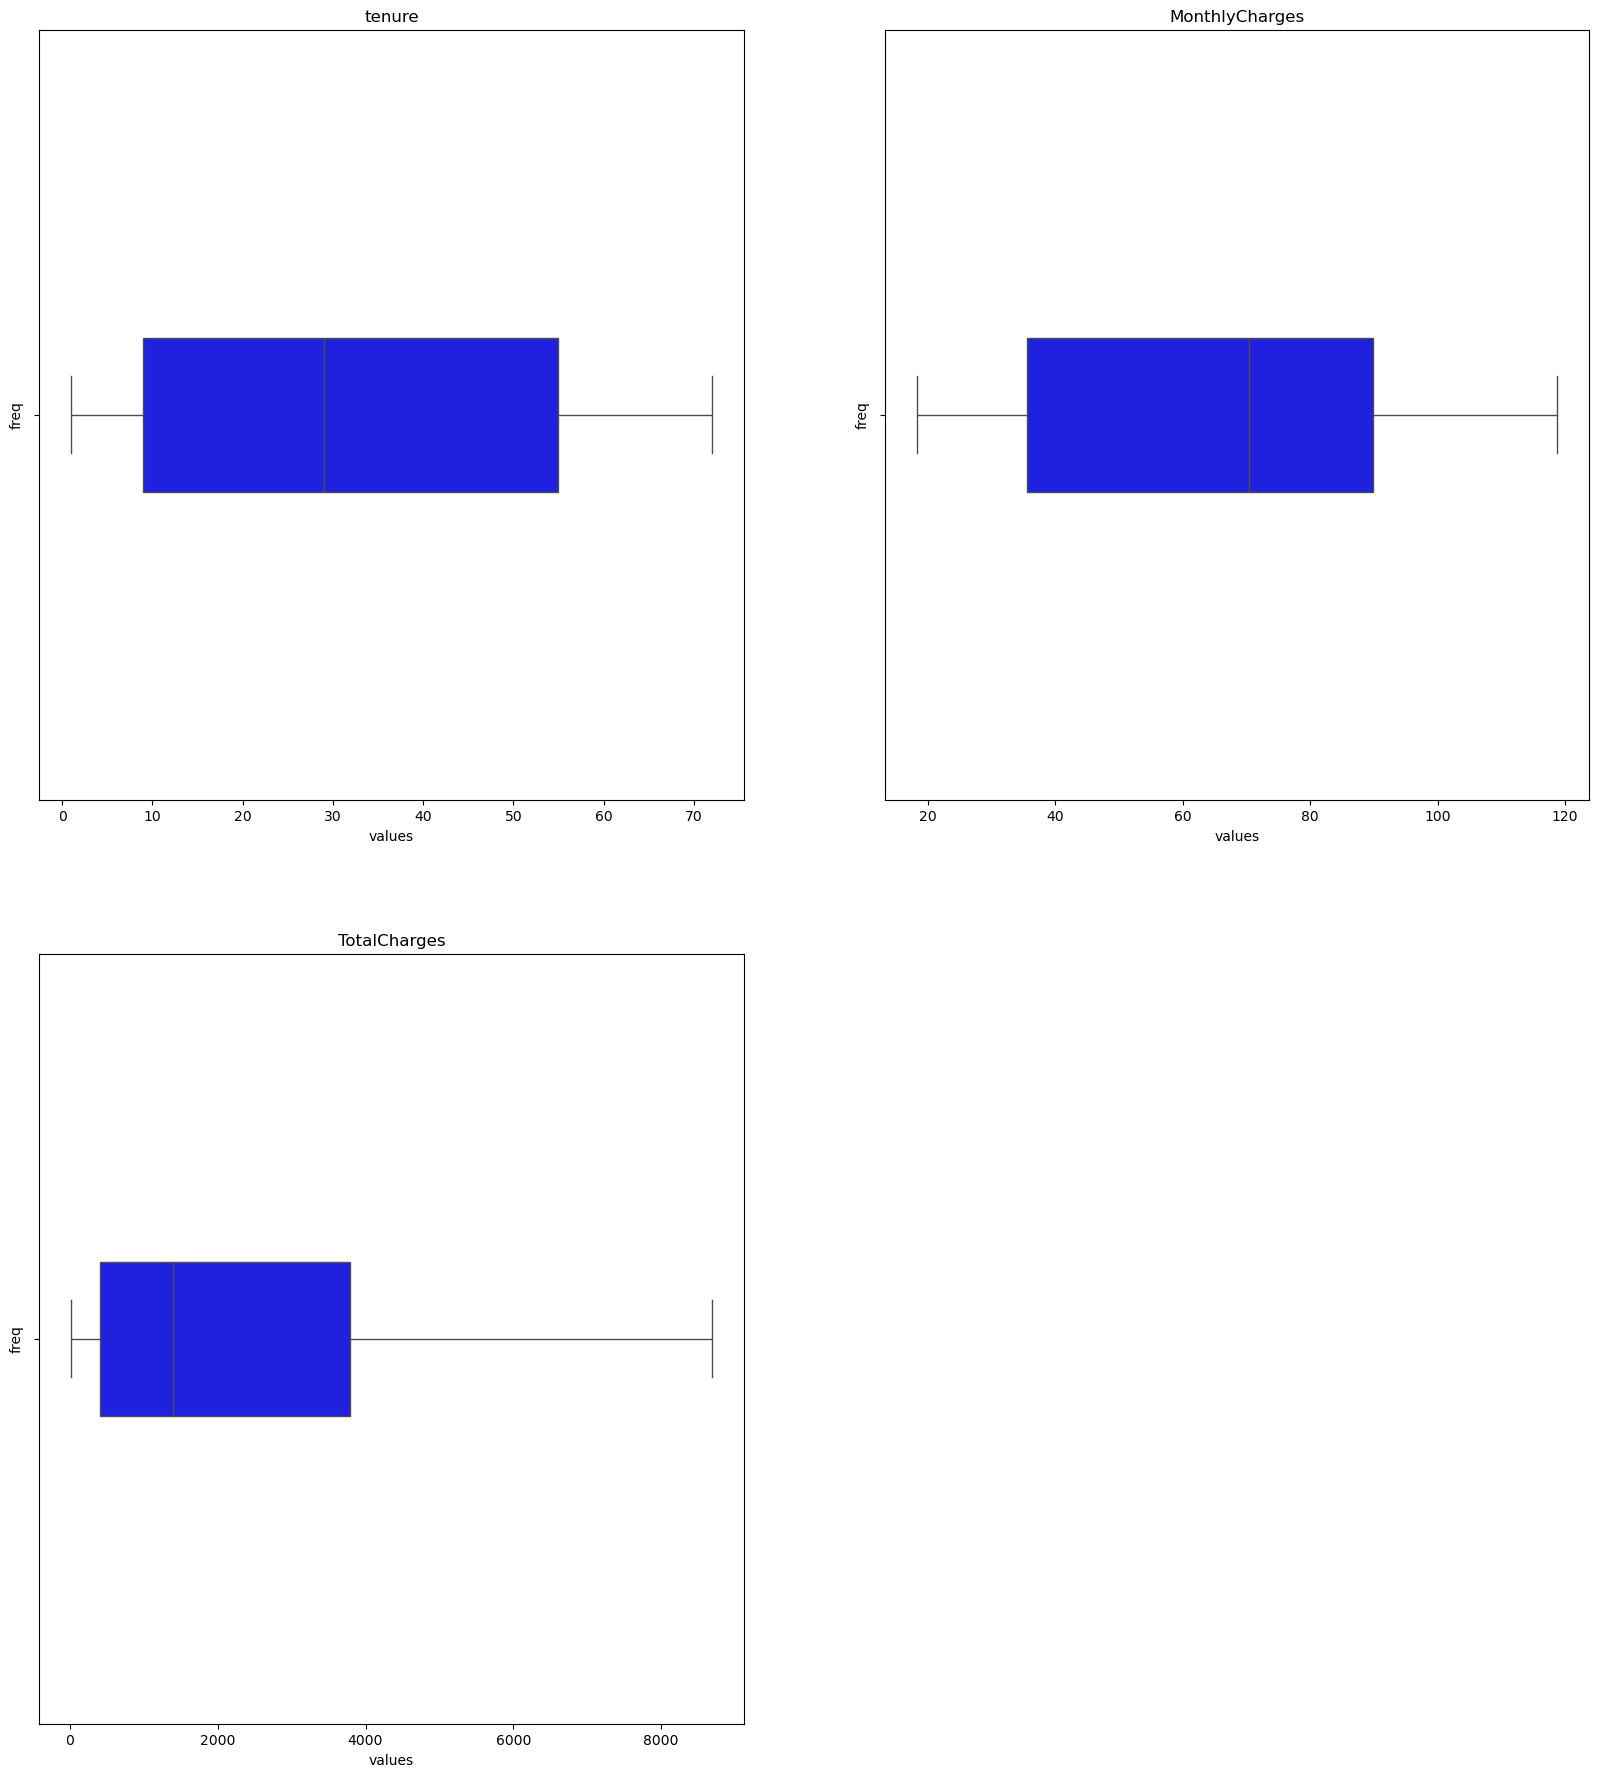

In [20]:
plt.figure(figsize=(20,22))
for i,col in enumerate(n_features):
    plt.subplot(2,2,i+1)
    sns.boxplot(x=dataframe[col],color="blue",width=0.2)
    plt.title(col)
    plt.ylabel('freq')
    plt.xlabel('values')

In [26]:
dataframe.groupby('Contract')['Churn'].value_counts()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1306
                Yes       166
Two year        No       1637
                Yes        48
Name: count, dtype: int64

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

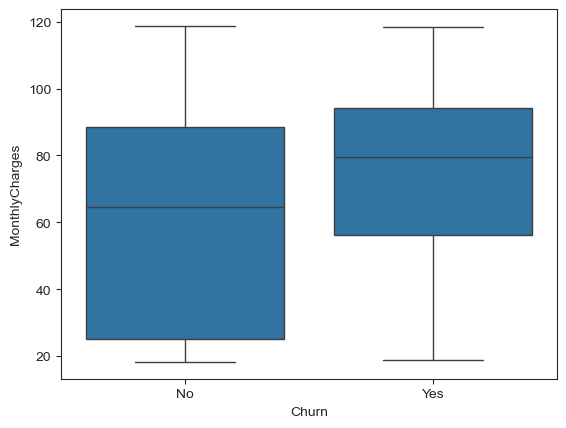

In [34]:
sns.set_style('ticks')
sns.boxplot(data=dataframe,x='Churn',y='MonthlyCharges')

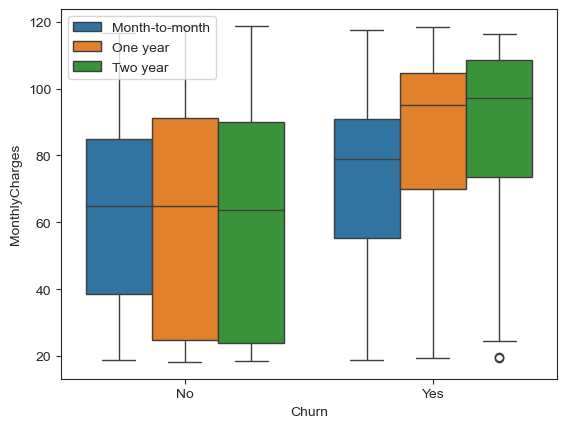

In [43]:
sns.boxplot(data=dataframe,x='Churn',y='MonthlyCharges',hue='Contract')
plt.legend(loc=2)
plt.show()

<Axes: xlabel='MonthlyCharges', ylabel='Count'>

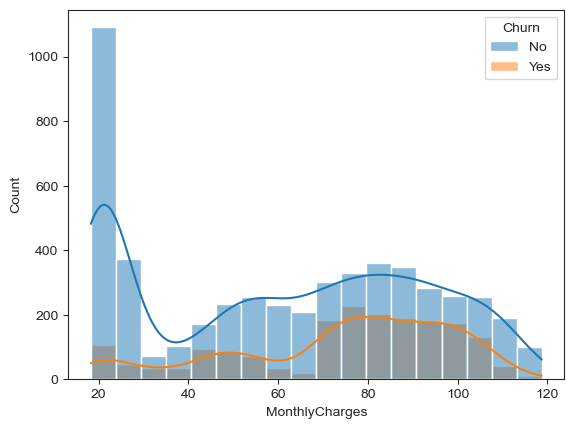

In [47]:
sns.histplot(data=dataframe, x='MonthlyCharges',kde=True,hue='Churn')

<Axes: xlabel='tenure', ylabel='MonthlyCharges'>

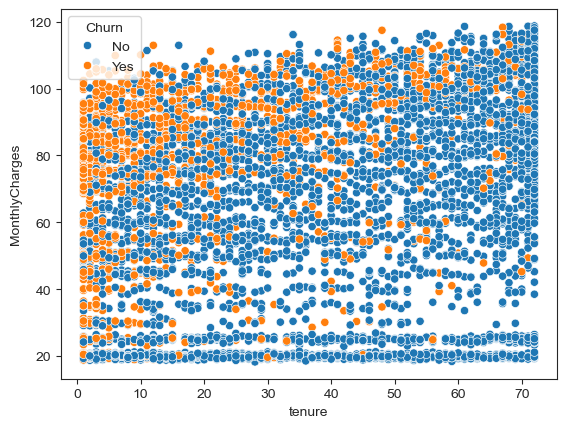

In [53]:
sns.scatterplot(data=dataframe, x='tenure',y='MonthlyCharges',hue='Churn')